# 09 · Set progression and prediction limits

**Why:** relative pixel speed did not fix nearly constant predictions. The experiments test whether completed rep count, lift timing, movement geometry or a capacity-then-countdown formulation helps.

**Protocol:** only completed reps are inputs, people remain separated across training and evaluation, and comparisons use matched examples. These are exploratory follow-ups on previously inspected participants.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    mean_absolute_error,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'training/results').is_dir()
)
OUTPUT = ROOT / 'training/results/set_progression_followup'
config = json.loads((OUTPUT / 'config.json').read_text())
display(pd.DataFrame(config['cohorts']).T)
RUN_TRAINING = False

,examples,people,videos,features_sha256
timing97,97,6,9,17c951aa6737ec0150b17b2875d8b15835015b66e5a4c1...
motion58,58,5,6,ce85a055e561c388adccc42b9c94fbd043f8677719ec10...
matched33,33,4,5,ddf75bb2d085a952ad8df99708bb2603b27b38117e0d0b...


## Inputs and experiments

- **Timing:** current lift/lower duration, their ratios to the first three reps, and the last four reps' timing trend. Compare with and without completed rep count.
- **Geometry:** completed-rep range, angular speed, left/right difference and elbow sway; correct x/y aspect ratio before calculating angles. Early range/speed references require at least two valid reps among the first three. This quality filter leaves a different, smaller cohort.
- **Capacity:** learn total set capacity from completed-prefix features, then subtract completed rep count. Capacity is a training target, never a test input.
- **Trees:** check a more flexible nonlinear estimator against timing and signal inputs.

First-three-rep references are available before the first estimate at rep four. No full-video duration, final count, participant ID or future rep is a model input. The input tables are derived numerical data; raw video is not packaged.

In [2]:
TIMING = [
    'initial_up',
    'current_up',
    'up_ratio',
    'recent_up_ratio',
    'up_trend',
    'current_down',
    'down_ratio',
    'max_up_ratio',
    'timing_cv',
]
GEOMETRY = [
    'range',
    'angular_speed',
    'asymmetry',
    'elbow_sway',
    'range_ratio',
    'angular_speed_ratio',
]
SIGNAL = [
    'speed_mean',
    'speed_p90',
    'speed_current',
    'speed_change',
    'transverse_log_rms',
    'transverse_power_fraction',
    'transverse_peak_fraction',
]
timing = pd.read_csv(OUTPUT / 'timing_features.csv')
geometry = pd.read_csv(OUTPUT / 'geometry_features.csv')
signal = pd.read_csv(OUTPUT / 'signal_context_features.csv')
for table in [timing, geometry, signal]:
    assert not table.duplicated(['video_id', 'rep']).any()
    assert table.rep.ge(4).all()
    assert np.isfinite(table.select_dtypes('number')).all().all()
print(
    'Timings come from reviewed start/top/end boundaries; app boundary errors can add further error.'
)

Timings come from reviewed start/top/end boundaries; app boundary errors can add further error.


In [3]:
def rebuild_timing_features(marks):
    records = []
    for video,g in marks.groupby('video_id',sort=False):
     g=g.sort_values('rep'); early=g.iloc[:3]; baseline=float((early.top_s-early.start_s).median())
     for idx in range(3,len(g)):
      h=g.iloc[:idx+1]; recent=h.iloc[-4:]; r=h.iloc[-1]; up=recent.top_s-recent.start_s; down=recent.end_s-recent.top_s; e_up=(early.top_s-early.start_s).to_numpy();e_down=(early.end_s-early.top_s).to_numpy()
      records.append({'video_id':video,'participant_id':r.participant_id,'rep':r.rep,'reps_left':r.reps_left,
       'completed_reps':r.rep,'elapsed':r.end_s-g.start_s.iloc[0],
       'initial_up':baseline,'current_up':up.iloc[-1],'up_ratio':up.iloc[-1]/baseline,
       'recent_up_ratio':up.mean()/baseline,'up_trend':np.polyfit(range(4),up.to_numpy()/baseline,1)[0],
       'current_down':down.iloc[-1],'down_ratio':down.iloc[-1]/max(.05,np.median(e_down)),
       'max_up_ratio':float(up.max())/baseline,'timing_cv':up.std()/up.mean()})
    return pd.DataFrame(records)

labels_path = ROOT / 'training/data/processed/reviewed_reps.csv'
if labels_path.exists():
    marks = pd.read_csv(labels_path)
    rebuilt = rebuild_timing_features(marks)
    columns = ['video_id', 'rep', *TIMING, 'completed_reps']
    pd.testing.assert_frame_equal(rebuilt[columns].sort_values(['video_id', 'rep']).reset_index(drop=True), timing[columns].sort_values(['video_id', 'rep']).reset_index(drop=True), check_dtype=False, atol=1e-12)
    original = marks.loc[marks.video_id.eq('Vfb5fee7743ec')].sort_values('rep')
    before = rebuild_timing_features(original).query('rep == 9')[TIMING + ['completed_reps']].to_numpy()
    changed = original.copy()
    for column in ['start_s', 'top_s', 'end_s']:
        changed.loc[changed.rep.gt(9), column] += 1000
    after = rebuild_timing_features(changed).query('rep == 9')[TIMING + ['completed_reps']].to_numpy()
    np.testing.assert_array_equal(before, after)
    print('Timestamp-feature reproduction and future-rep invariance checks passed.')


Timestamp-feature reproduction and future-rep invariance checks passed.


## Model comparison methods

Ridge and SVR each compare four regularization values; shallow boosting compares two settings; ExtraTrees compares three leaf sizes. Inner folds select settings without the held-out person. Capacity models use the same inner RIR error criterion. Regression predictions are floored at zero; classification uses a fixed 0.5 threshold.

These exploratory comparisons include unsuccessful variants and do not provide a new independent test set.

In [4]:
def run_comparisons():
    from sklearn.linear_model import Ridge, LogisticRegression
    from sklearn.svm import SVR
    from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier, ExtraTreesRegressor
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    specifications = []
    for cohort, table, groups in [
        ('timing97', timing, {'timing': TIMING, 'count_timing': ['completed_reps', *TIMING], 'count_only': ['completed_reps']}),
        ('motion58', geometry, {'motion': GEOMETRY, 'timing_motion': TIMING + GEOMETRY, 'count_timing_motion': ['completed_reps', *TIMING, *GEOMETRY]})]:
        for group, columns in groups.items():
            for task in ['regression', 'classification']:
                for kind in (['ridge', 'svr', 'boost'] if task == 'regression' else ['ridge', 'boost']):
                    specifications.append((cohort, table, group + '_' + kind, columns, kind, task, False))
    for group, columns in {'initial_only': ['initial_up'], 'timing': TIMING, 'count_timing': ['completed_reps', *TIMING]}.items():
        for kind in ['ridge', 'svr', 'boost']:
            specifications.append(('capacity97', timing, group + '_' + kind, columns, kind, 'regression', True))
    for cohort, table, groups in [
        ('timing97', timing, {'timing': TIMING, 'progress_timing': ['completed_reps', *TIMING]}),
        ('matched33', signal, {'signal': SIGNAL, 'progress_signal': ['completed_reps', *SIGNAL], 'all': ['completed_reps', *TIMING, *SIGNAL]})]:
        for group, columns in groups.items():
            specifications.append((cohort, table, 'trees_' + group, columns, 'trees', 'regression', False))
    def fit(table, columns, kind, parameter, task, capacity):
        if task == 'classification':
            estimator = LogisticRegression(C=parameter, class_weight='balanced', max_iter=1000) if kind == 'ridge' else HistGradientBoostingClassifier(max_iter=80, max_leaf_nodes=4, min_samples_leaf=8, l2_regularization=parameter, random_state=42, class_weight='balanced')
        elif kind == 'ridge':
            estimator = Ridge(alpha=parameter)
        elif kind == 'svr':
            estimator = SVR(C=parameter, epsilon=.5)
        elif kind == 'trees':
            estimator = ExtraTreesRegressor(n_estimators=100, min_samples_leaf=parameter, max_features=1., random_state=42, n_jobs=2)
        else:
            estimator = HistGradientBoostingRegressor(max_iter=80, max_leaf_nodes=4, min_samples_leaf=8, l2_regularization=parameter, random_state=42)
        weights = (1 / table.groupby('participant_id').participant_id.transform('size')).to_numpy(copy=True)
        weights *= len(weights) / weights.sum()
        target = table.reps_left.le(2) if task == 'classification' else table.reps_left + table.rep if capacity else table.reps_left
        if kind == 'trees':
            return estimator.fit(table[columns], target, sample_weight=weights)
        model = make_pipeline(StandardScaler(), estimator)
        model.fit(table[columns], target, **{model.steps[-1][0] + '__sample_weight': weights})
        return model
    def predict(model, data, columns, task, capacity):
        if task == 'classification':
            return model.predict_proba(data[columns])[:, 1]
        values = model.predict(data[columns])
        return np.maximum(0, values - data.rep.to_numpy() if capacity else values)
    def loss(data, values, task):
        errors = []
        for person, group in data.groupby('participant_id'):
            selected = values[data.participant_id.eq(person)]
            errors.append(mean_absolute_error(group.reps_left, selected) if task == 'regression' else 1 - balanced_accuracy_score(group.reps_left.le(2), selected >= .5))
        return float(np.mean(errors))
    predictions, selections = [], []
    for cohort, table, name, columns, kind, task, capacity in specifications:
        parameters = [1, 3, 6] if kind == 'trees' else [1., 10.] if kind == 'boost' else [.1, 1., 10., 100.]
        print(cohort, name, task, flush=True)
        for person in sorted(table.participant_id.unique()):
            train, test = table.loc[table.participant_id.ne(person)], table.loc[table.participant_id.eq(person)]
            assert set(train.participant_id).isdisjoint(test.participant_id)
            candidates = []
            for parameter in parameters:
                scores = []
                for validation_person in sorted(train.participant_id.unique()):
                    a = train.loc[train.participant_id.ne(validation_person)]
                    b = train.loc[train.participant_id.eq(validation_person)]
                    values = predict(fit(a, columns, kind, parameter, task, capacity), b, columns, task, capacity)
                    scores.append(loss(b, values, task))
                candidates.append((float(np.mean(scores)), parameter))
            score, parameter = min(candidates)
            model = fit(train, columns, kind, parameter, task, capacity)
            record = test[['participant_id', 'video_id', 'rep', 'reps_left']].copy()
            record['prediction'] = predict(model, test, columns, task, capacity)
            record['cohort'], record['model'], record['task'] = cohort, name, task
            predictions.append(record)
            selections.append({'cohort': cohort, 'model': name, 'task': task, 'test_person': person, 'parameter': parameter, 'inner_loss': score})
    pd.concat(predictions, ignore_index=True).to_csv(OUTPUT / 'predictions.csv', index=False)
    pd.DataFrame(selections).to_csv(OUTPUT / 'inner_selection.csv', index=False)

if RUN_TRAINING:
    run_comparisons()

## Results · matched cohorts only

MAE and final-rep MAE describe RIR regression. Balanced accuracy, precision, recall and F1 describe the separate RIR ≤ 2 classifier. Scores average people equally. The geometry and signal-context cohorts have fewer examples; their errors must not be ranked against the 97-example cohort.

In [5]:
predictions = pd.read_csv(OUTPUT / 'predictions.csv')
records = []
for (cohort, task, model, person), group in predictions.groupby(['cohort', 'task', 'model', 'participant_id']):
    assert not group.duplicated(['video_id', 'rep']).any()
    row = {'cohort': cohort, 'task': task, 'model': model, 'participant_id': person, 'examples': len(group)}
    if task == 'regression':
        error = group.prediction - group.reps_left
        near = group.reps_left.le(2)
        row.update(mae=error.abs().mean(), rmse=np.sqrt(np.mean(error ** 2)), within_1=(error.abs() <= 1).mean(), within_2=(error.abs() <= 2).mean(), bias=error.mean(), near_failure_mae=error.loc[near].abs().mean(), final_rep_mae=group.loc[group.reps_left.eq(0), 'prediction'].abs().mean())
    else:
        truth = group.reps_left.le(2); guess = group.prediction.ge(.5)
        row.update(balanced_accuracy=balanced_accuracy_score(truth, guess), precision=precision_score(truth, guess, zero_division=0), recall=recall_score(truth, guess, zero_division=0), f1=f1_score(truth, guess, zero_division=0))
    records.append(row)
people = pd.DataFrame(records)
people.to_csv(OUTPUT / 'participant_scores.csv', index=False)
metrics = [c for c in people.select_dtypes('number').columns if c != 'examples']
summary = people.groupby(['cohort', 'task', 'model'])[metrics].mean()
counts = people.groupby(['cohort', 'task', 'model']).agg(examples=('examples', 'sum'), people=('participant_id', 'nunique'))
summary = summary.join(counts).reset_index()
summary.to_csv(OUTPUT / 'comparison.csv', index=False)
display(summary.loc[summary.task.eq('regression'), ['cohort', 'model', 'mae', 'near_failure_mae', 'final_rep_mae', 'examples', 'people']].round(3))
display(summary.loc[summary.task.eq('classification'), ['cohort', 'model', 'balanced_accuracy', 'precision', 'recall', 'f1', 'examples', 'people']].round(3))

,cohort,model,mae,near_failure_mae,final_rep_mae,examples,people
0,capacity97,count_timing_boost,8.606,6.547,6.190,97,6
1,capacity97,count_timing_ridge,6.524,4.805,3.469,97,6
2,capacity97,count_timing_svr,6.588,3.731,3.140,97,6
3,capacity97,initial_only_boost,10.187,7.515,7.181,97,6
4,capacity97,initial_only_ridge,9.298,7.384,7.050,97,6
5,capacity97,initial_only_svr,7.019,4.127,3.794,97,6
6,capacity97,timing_boost,9.654,7.433,7.068,97,6
7,capacity97,timing_ridge,9.085,7.990,6.498,97,6
8,capacity97,timing_svr,6.510,3.661,3.208,97,6
9,matched33,trees_all,2.563,3.581,5.066,33,4


,cohort,model,balanced_accuracy,precision,recall,f1,examples,people
12,motion58,count_timing_motion_boost,0.625,0.458,0.667,0.446,58,5
13,motion58,count_timing_motion_ridge,0.553,0.340,0.467,0.300,58,5
14,motion58,motion_boost,0.535,0.269,0.567,0.340,58,5
15,motion58,motion_ridge,0.571,0.436,0.433,0.340,58,5
16,motion58,timing_motion_boost,0.618,0.455,0.667,0.443,58,5
17,motion58,timing_motion_ridge,0.579,0.538,0.533,0.396,58,5
27,timing97,count_only_boost,0.564,0.281,0.667,0.379,97,6
28,timing97,count_only_ridge,0.587,0.302,0.444,0.294,97,6
29,timing97,count_timing_boost,0.651,0.541,0.694,0.500,97,6
30,timing97,count_timing_ridge,0.652,0.480,0.472,0.403,97,6


Historical video-model references restricted to the same 97 reps; seed-averaged errors:


,model,mae,examples,people,run
0,lstm,4.677,97,6,pilot_20261030T154433983651Z
1,tcn,5.724,97,6,pilot_20261030T154433983651Z
2,training_median,4.941,97,6,pilot_20261030T154433983651Z
3,r3d_adapter_tcn,4.837,97,6,r3d_history_20261030T183202356628Z
4,r3d_adapter_tcn_prefix,5.185,97,6,r3d_history_20261030T183202356628Z
5,training_median,4.941,97,6,r3d_history_20261030T183202356628Z


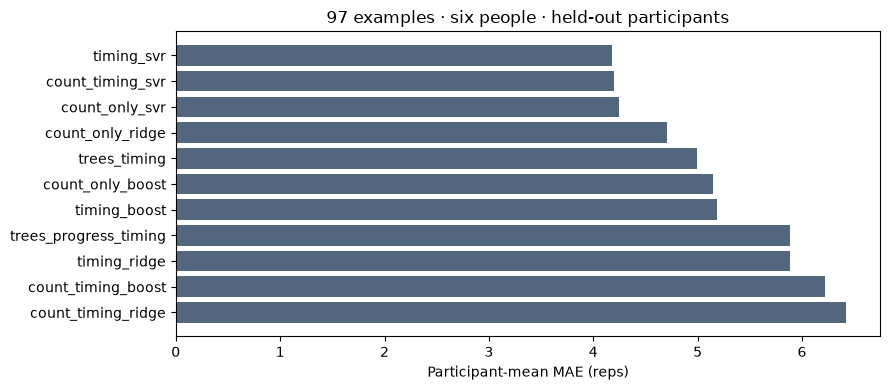

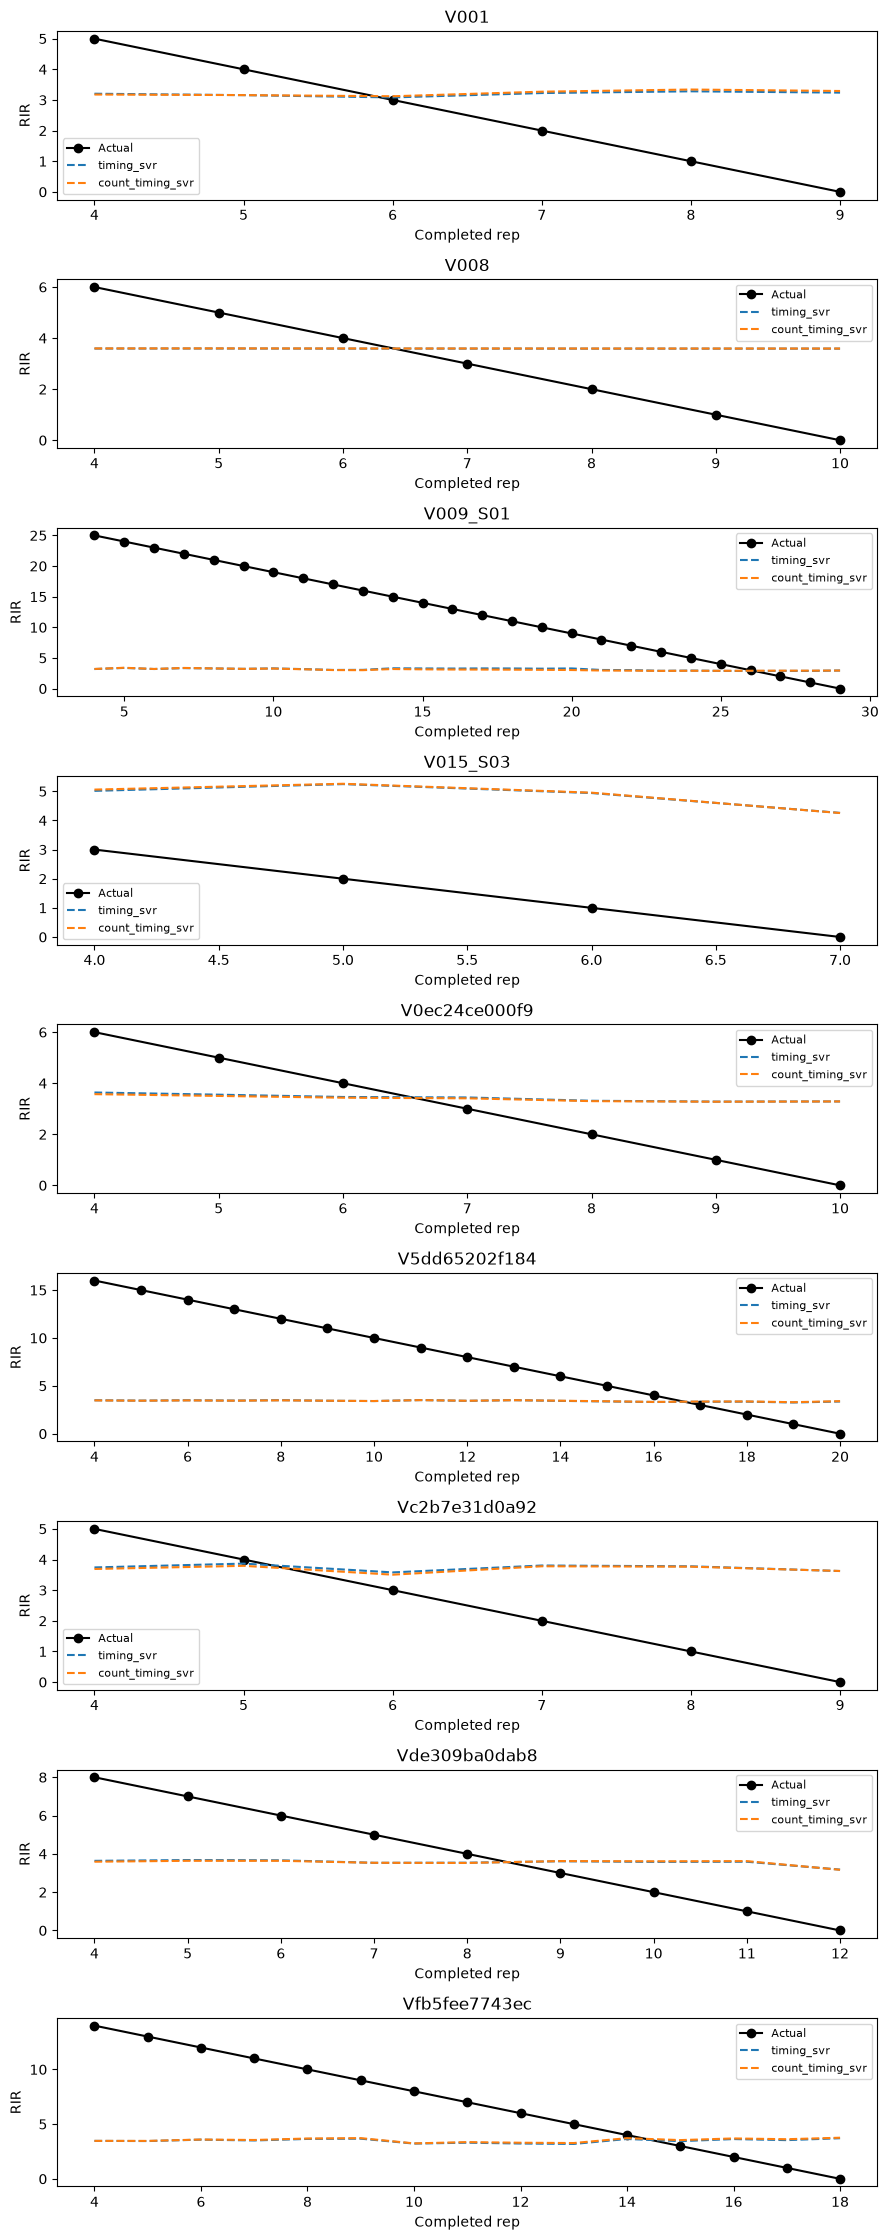

In [6]:
keys = timing[['participant_id', 'video_id', 'rep']]
historical = []
for run in ['pilot_20261030T154433983651Z', 'r3d_history_20261030T183202356628Z']:
    old = pd.read_csv(ROOT / 'training/results' / run / 'predictions.csv').merge(keys, on=['participant_id', 'video_id', 'rep'], validate='many_to_one')
    for model, group in old.groupby('model'):
        scores = group.assign(error=(group.prediction - group.reps_left).abs()).groupby(['seed', 'participant_id']).error.mean()
        historical.append({'model': model, 'mae': float(scores.groupby('seed').mean().mean()), 'examples': len(keys), 'people': keys.participant_id.nunique(), 'run': run})
historical = pd.DataFrame(historical)
historical.to_csv(OUTPUT / 'matched_video_references.csv', index=False)
print('Historical video-model references restricted to the same 97 reps; seed-averaged errors:')
display(historical.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
selected = summary.loc[summary.cohort.eq('timing97') & summary.task.eq('regression')].sort_values('mae')
ax.barh(selected.model, selected.mae, color='#52677d'); ax.invert_yaxis()
ax.set(xlabel='Participant-mean MAE (reps)', title='97 examples · six people · held-out participants')
fig.tight_layout(); fig.savefig(OUTPUT / 'timing_comparison.png', dpi=150); plt.show()

group = predictions.loc[predictions.cohort.eq('timing97') & predictions.task.eq('regression')]
videos = sorted(group.video_id.unique())
fig, axes = plt.subplots(len(videos), 1, figsize=(9, 2.5 * len(videos)), squeeze=False)
for ax, video in zip(axes[:, 0], videos):
    part = group.loc[group.video_id.eq(video)]
    truth = part.drop_duplicates('rep').sort_values('rep')
    ax.plot(truth.rep, truth.reps_left, 'ko-', label='Actual')
    for name in ['timing_svr', 'count_timing_svr']:
        line = part.loc[part.model.eq(name)].sort_values('rep')
        ax.plot(line.rep, line.prediction, '--', label=name)
    ax.set(title=video, xlabel='Completed rep', ylabel='RIR'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT / 'set_predictions.png', dpi=120); plt.show()

## Decision

The broad timing-only SVR reaches about **4.18 reps MAE** on 97 examples from six people. On those same reps, the historical R3D model is about **4.84**, and the median baseline is about **4.94**. This exploratory improvement does not establish the proposed shaking-versus-speed benefit.

Final-rep predictions remain weak, and video 3 is unresolved. Geometry, capacity/countdown and flexible trees did not provide a reliable replacement. Fitting training clips alone is not evidence of generalization.

The completed-set review calculates **observed reps remaining** only after a user confirms failure and reviews rep boundaries. Those values are separate from the experimental model predictions. Accurate exact-RIR generalization remains unproven.

References motivating the progression checks: [individual RIR–velocity relationships](https://pmc.ncbi.nlm.nih.gov/articles/PMC10901726/) and [limitations of velocity-based RIR](https://pubmed.ncbi.nlm.nih.gov/37552530/).